# Structured Data Extraction from Scientific Literature with a Local LLM

**Author:** Juan Jesús Gómez Ortiz · MSc in Big Data Science, University of Navarra

## Context

A pharmaceutical company wants to develop new drugs and design new experiments. Published research is public, and reviewing it is a large, manual task. The goal is to turn a set of research articles (PDF) into **one table: one row per article, one column per variable of interest**. When a variable does not appear in an article, it is stored as a null value (never invented).

## Approach

A hybrid pipeline, using each tool where it is most reliable:

- **Regular expressions** for fields that always follow the same format: DOI, year, citation style, number of references and the most cited reference.
- **A local LLM from Hugging Face** (`Qwen2.5-3B-Instruct`) for fields that require understanding the text: title, first author, study type, number of participants and country. The model reads the first page (title, authors, abstract) and answers in JSON. It runs on the laptop, so no document leaves the machine.
- **Validation** of the LLM's answers against a manual review of every article.

The code lives in [`src/`](../src): `pdf_reader.py`, `rule_extractors.py` and `llm_extractor.py`.

In [1]:
import sys
sys.path.insert(0, "..")          # make src/ importable from notebooks/

import pandas as pd
import matplotlib.pyplot as plt

from src.pdf_reader import read_pdf, read_folder
from src.rule_extractors import extract_with_rules
from src.llm_extractor import LLMExtractor, DEFAULT_MODEL

PDF_FOLDER = "../data/pdfs"

## 1. Text extraction

`PyMuPDF` reads every page. The text is normalised (NFKC) to undo typographic ligatures (`ﬁ`, `ﬂ`, `ﬀ`) that would break the searches.

In [2]:
texts = read_folder(PDF_FOLDER)
for name in texts:
    _, n_pages = read_pdf(f"{PDF_FOLDER}/{name}")
    print(f"{name:24} {n_pages:>2} pages  {len(texts[name]):>6} characters")

fpsyg-08-00308.pdf       11 pages   58288 characters
fpsyg-09-01240.pdf       15 pages   76709 characters
fpsyg-11-01354.pdf        9 pages   59565 characters


fpsyg-12-639236.pdf      16 pages   87158 characters
fpsyt-14-1301143.pdf      7 pages   48577 characters
fpubh-10-1045777.pdf     12 pages   43696 characters


## 2. Rule-based fields

DOI and year are always on the first page in the same format. For citations there are two styles: author-year (`Flaten, 2008`) and numeric (`[15]`). In the numeric style the most cited number is found and translated into author and year using the reference list.

In [3]:
rules = pd.DataFrame({name: extract_with_rules(t) for name, t in texts.items()}).T
rules

,doi,year,citation_style,n_references,most_cited_reference,times_cited
fpsyg-08-00308.pdf,10.3389/fpsyg.2017.00308,2017,author-year,61,"Peciña et al., 2013",5
fpsyg-09-01240.pdf,10.3389/fpsyg.2018.01240,2018,author-year,114,"Hui and Zhou, 1998",5
fpsyg-11-01354.pdf,10.3389/fpsyg.2020.01354,2020,author-year,99,"Kaptchuk et al., 2008",4
fpsyg-12-639236.pdf,10.3389/fpsyg.2021.639236,2021,author-year,72,"Daniali and Flaten, 2019",6
fpsyt-14-1301143.pdf,10.3389/fpsyt.2023.1301143,2024,numeric,78,"[15] Albert, 2019",5
fpubh-10-1045777.pdf,10.3389/fpubh.2022.1045777,2023,numeric,30,"[10] Beck, 1970",4


## 3. Local LLM from Hugging Face

`Qwen/Qwen2.5-3B-Instruct` runs with `transformers` on the Mac GPU (`mps`), with greedy decoding so the answers are deterministic. Only the beginning of each article is passed to the model, which is where the requested information is.

In [4]:
llm = LLMExtractor(DEFAULT_MODEL)
print("Model", DEFAULT_MODEL, "loaded on", llm.device)

# Test with the first article: raw answer and parsed fields
first = next(iter(texts.values()))
print(llm.ask(first))
llm.extract(first)

Model Qwen/Qwen2.5-3B-Instruct loaded on mps


{
"first_author": "Corsi",
"study_type": "experimental",
"n_participants": 46,
"country": "USA",
"title": "Placebo and Nocebo Effects: The Advantage of Measuring Expectations and Psychological Factors"
}


{'first_author': 'Corsi',
 'study_type': 'experimental',
 'n_participants': 46,
 'country': 'United States',
 'title': 'Placebo and Nocebo Effects: The Advantage of Measuring Expectations and Psychological Factors'}

## 4. Final table

One row per article, one column per variable. Fields that do not appear in an article stay null (`<NA>`).

In [5]:
rows = []
for name, text in texts.items():
    fields = llm.extract(text)
    r = extract_with_rules(text)
    rows.append({
        "file": name,
        "title": fields["title"],
        "first_author": fields["first_author"],
        "year": r["year"],
        "doi": r["doi"],
        "study_type": fields["study_type"],
        "n_participants": fields["n_participants"],
        "country": fields["country"],
        "citation_style": r["citation_style"],
        "n_references": r["n_references"],
        "most_cited_reference": r["most_cited_reference"],
        "times_cited": r["times_cited"],
    })

table = pd.DataFrame(rows).convert_dtypes()
table.to_csv("../data/extracted_table.csv", index=False)
table

,file,title,first_author,year,doi,study_type,n_participants,country,citation_style,n_references,most_cited_reference,times_cited
0,fpsyg-08-00308.pdf,Placebo and Nocebo Effects: The Advantage of M...,Corsi,2017,10.3389/fpsyg.2017.00308,experimental,46,United States,author-year,61,"Peciña et al., 2013",5
1,fpsyg-09-01240.pdf,Application of Bayes’ Theorem in Valuating Dep...,Tommasi,2018,10.3389/fpsyg.2018.01240,review/theoretical,<NA>,Italy,author-year,114,"Hui and Zhou, 1998",5
2,fpsyg-11-01354.pdf,Putting the ‘Art’ Into the ‘Art of Medicine’: ...,Bernstein,2020,10.3389/fpsyg.2020.01354,review/theoretical,<NA>,United States,author-year,99,"Kaptchuk et al., 2008",4
3,fpsyg-12-639236.pdf,"Placebo Effects on Stress, but Not on Pain Rep...",Vambheim,2021,10.3389/fpsyg.2021.639236,experimental,152,Norway,author-year,72,"Daniali and Flaten, 2019",6
4,fpsyt-14-1301143.pdf,Placebo stimulates neuroplasticity in depressi...,Seymour,2024,10.3389/fpsyt.2023.1301143,review/theoretical,<NA>,United Kingdom,numeric,78,"[15] Albert, 2019",5
5,fpubh-10-1045777.pdf,Cognitive distortion based explainable depress...,Wang,2023,10.3389/fpubh.2022.1045777,computational,<NA>,China,numeric,30,"[10] Beck, 1970",4


## 5. Validation

The LLM's answers are compared with the values reviewed by hand in each article ([`data/ground_truth.csv`](../data/ground_truth.csv)). Note that Vambheim et al. (2021) report two experiments: 152 = 59 + 93 participants.

In [6]:
truth = pd.read_csv("../data/ground_truth.csv").set_index("file")
pred = table.set_index("file")[truth.columns]

def matches(t, p):
    if pd.isna(t) or pd.isna(p):
        return pd.isna(t) and pd.isna(p)
    if isinstance(t, (int, float)):
        return float(t) == float(p)
    return str(t).lower() == str(p).lower()

hits = pd.DataFrame({col: [matches(t, p) for t, p in zip(truth[col], pred.loc[truth.index, col])]
                     for col in truth.columns}, index=truth.index)

print("LLM accuracy per field:")
print(hits.mean().round(2).to_string())
print(f"\nOverall: {hits.values.sum()} / {hits.size} fields correct")
hits

LLM accuracy per field:
first_author      1.00
study_type        0.83
n_participants    1.00
country           1.00

Overall: 23 / 24 fields correct


,first_author,study_type,n_participants,country
file,,,,
fpsyg-08-00308.pdf,True,True,True,True
fpsyg-09-01240.pdf,True,False,True,True
fpsyg-11-01354.pdf,True,True,True,True
fpsyg-12-639236.pdf,True,True,True,True
fpsyt-14-1301143.pdf,True,True,True,True
fpubh-10-1045777.pdf,True,True,True,True


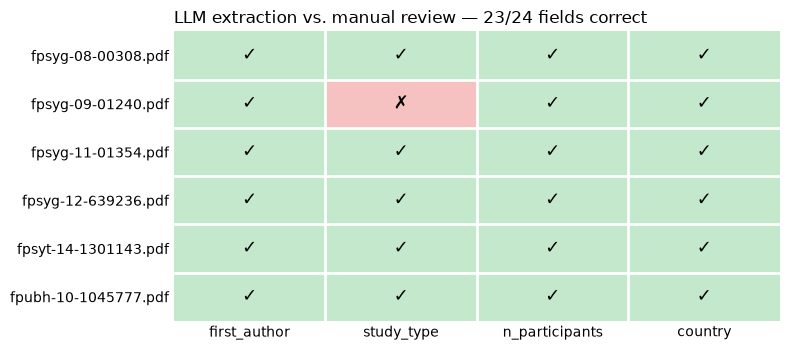

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.6))
from matplotlib.colors import ListedColormap
ax.imshow(hits.astype(int).values, cmap=ListedColormap(["#f6c1c1", "#c4e8cb"]), vmin=0, vmax=1, aspect="auto")
ax.set_xticks([x - .5 for x in range(1, hits.shape[1])], minor=True)
ax.set_yticks([y - .5 for y in range(1, hits.shape[0])], minor=True)
ax.grid(which="minor", color="white", lw=2)
for s in ax.spines.values(): s.set_visible(False)
ax.set_xticks(range(hits.shape[1]), hits.columns)
ax.set_yticks(range(hits.shape[0]), hits.index)
for i in range(hits.shape[0]):
    for j in range(hits.shape[1]):
        ax.text(j, i, "✓" if hits.iat[i, j] else "✗", ha="center", va="center", fontsize=13)
ax.set_title(f"LLM extraction vs. manual review — {hits.values.sum()}/{hits.size} fields correct", loc="left")
ax.tick_params(which="both", length=0)
plt.tight_layout(); fig.savefig("../images/01_validation_matrix.png", dpi=150); plt.show()

## 6. Difficulties found

- The first model tested, `Qwen2.5-1.5B`, was faster but confused the first author with the corresponding author and did not find the participants. The 3B model gets them right.
- When the title was the first field requested in the prompt, other fields failed; asking for it last fixed it (see [`docs/prompt_design.md`](../docs/prompt_design.md)).
- Each journal cites differently (author-year or numeric), so each style needed its own rule.
- **Small models are sensitive to wording.** In the first version of this project the JSON keys and category labels were in Spanish (with the same English instructions) and all 24 fields were correct. With English labels, the 3B model classifies Tommasi et al. (2018), which evaluates a statistical method for depression tests, as `review/theoretical` instead of `methodological`. The prompt was not re-tuned on these same six articles, because that would overfit the evaluation set.

## 7. Limitations

- Six articles is a small sample: the result shows the pipeline works, not that it generalises. A larger, labelled set is needed to measure precision and recall per field.
- Rule-based fields depend on the publisher's layout (here, Frontiers); other publishers would need their own patterns.